# Results section 5, second half, and Figure 4

## Setup

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

warnings.filterwarnings("ignore")
%matplotlib inline

# the package root is the folder that holds Data/
def _root(start=None):
    here = Path(__file__).resolve() if "__file__" in globals() else Path.cwd().resolve()
    for c in (here, *here.parents):
        if (c / "Data" / "conversation_turns.csv").exists():
            return c
    raise RuntimeError(f"cannot find the package root (no Data/conversation_turns.csv at or above {here})")

ROOT   = _root()
CLEAN  = ROOT / "Data"
FIGDIR = ROOT / "Code" / "_output" / "figures"; FIGDIR.mkdir(parents=True, exist_ok=True)
RESDIR = ROOT / "Code" / "_output" / "results"; RESDIR.mkdir(parents=True, exist_ok=True)

COL = {"partner": "#00798C", "own": "#D1495B", "solo": "#2B4C7E",
       "grey": "#6E6E6E", "light": "#BFBFBF", "third": "#E8871A"}
SINGLE, DOUBLE = 3.46, 7.09

mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 6.5, "axes.labelsize": 7, "axes.titlesize": 7.5,
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "lines.linewidth": 1.3, "lines.markersize": 3.5,
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02, "pdf.fonttype": 42, "ps.fonttype": 42,
})

def panel(ax, letter, title=None, dx=None, dy=None):
    # panel letter at the axes' left edge, in figure coordinates
    fg = ax.figure; bb = ax.get_position()
    fg.text(bb.x0, bb.y1 + .014, letter, fontsize=8, fontweight="bold",
            va="bottom", ha="left")
    if title:
        # title on the letter's baseline, a fixed 0.135 in to its right
        fg.text(bb.x0 + 0.135 / fg.get_size_inches()[0], bb.y1 + .014, title,
                fontsize=6.8, va="bottom", ha="left", color="#2A2A2A")

def close_corner(fig):
    # move each lower axis limit to the first tick when no data lie below it
    for ax in fig.axes:
        if not ax.axison:
            continue
        for get_lim, set_lim, ticks_of, data_lo in (
                (ax.get_xlim, ax.set_xlim, ax.get_xticks, lambda: ax.dataLim.x0),
                (ax.get_ylim, ax.set_ylim, ax.get_yticks, lambda: ax.dataLim.y0)):
            lo, hi = get_lim()
            if hi <= lo:
                continue
            inside = [t for t in ticks_of() if lo <= t <= hi]
            if not inside:
                continue
            first = min(inside)
            if first <= lo:
                continue
            d = data_lo()
            # leave a small gap between the axis and the nearest data point
            if d != d or d < first + (hi - lo) * 0.03:
                continue
            set_lim(first, hi)
        ax.spines["left"].set_bounds(*ax.get_ylim())
        ax.spines["bottom"].set_bounds(*ax.get_xlim())

def save(fig, name):
    fig.savefig(FIGDIR / f"{name}.pdf")
    fig.savefig(FIGDIR / f"{name}.tif", dpi=300, pil_kwargs={"compression": "tiff_lzw"})
    print(f"wrote {name}.pdf and .tif to Code/_output/figures/")

### Helper functions

In [2]:
def raincloud(ax, groups, colors, labels=None, width=.32, jitter=.075, ms=2.6,
              seed=0, alpha_pts=.40, show_n=False):
    # half a density on the right, the raw points on the left, a quartile bar between them
    rg = np.random.default_rng(seed)
    for i, (vals, c) in enumerate(zip(groups, colors)):
        v = np.asarray(vals, float); v = v[np.isfinite(v)]
        if len(v) > 4 and v.std() > 0:
            kde = stats.gaussian_kde(v)
            grid = np.linspace(v.min() - .05 * np.ptp(v), v.max() + .05 * np.ptp(v), 200)
            d = kde(grid); d = d / d.max() * width
            ax.fill_betweenx(grid, i + .07, i + .07 + d, color=c, alpha=.28, lw=0, zorder=2)
            ax.plot(i + .07 + d, grid, color=c, lw=.7, zorder=3)
        x = i - .13 - np.abs(rg.normal(0, jitter, len(v)))
        ax.scatter(x, v, s=ms, color=c, alpha=alpha_pts, edgecolors="none", zorder=2)
        q1, med, q3 = np.percentile(v, [25, 50, 75])
        ax.plot([i, i], [q1, q3], color=c, lw=3.2, solid_capstyle="butt", zorder=5)
        ax.plot([i], [med], "o", color="white", ms=2.8, mec=c, mew=.7, zorder=6)
        if show_n:
            ax.text(i, ax.get_ylim()[0], f"n = {len(v)}", ha="center", va="bottom",
                    fontsize=5.4, color=COL["grey"])
    ax.set_xticks(range(len(groups)))
    if labels:
        ax.set_xticklabels(labels)
    ax.set_xlim(-.55, len(groups) - .45)

def paired_effect(x, y, unit_label, names=("first", "second")):
    d = np.asarray(y) - np.asarray(x)
    n = len(d); m, sd = d.mean(), d.std(ddof=1)
    se = sd / np.sqrt(n)
    tc = stats.t.ppf(0.975, n - 1)
    t = stats.ttest_rel(y, x)
    print(f"    {names[1]} - {names[0]} = {m:+.3f}   95% CI "
          f"[{m - tc*se:+.3f}, {m + tc*se:+.3f}]   "
          f"t({n-1}) = {t.statistic:+.2f}, p = {t.pvalue:.1e}")
    print(f"    Cohen's dz = {m / sd:+.2f}   ({unit_label}, n = {n})")
    return m, m / sd

## 1 · Data

In [3]:
RECALL = pd.read_csv(CLEAN / "individual_recall.csv")
TURNS  = pd.read_csv(CLEAN / "conversation_turns.csv").sort_values(
    ["conversation", "turn_index"])
STIM   = pd.read_csv(CLEAN / "stimuli.csv")
ITEM   = {int(i): int(l) for i, l in zip(STIM[~STIM.is_lure].item_id,
                                        STIM[~STIM.is_lure].list)}

# each recall as (category or None, studied id or None) in output order; lures carry their
# list's category, intrusions carry none
def _stream(phase):
    d = RECALL[RECALL.phase == phase].sort_values(["participant", "output_position"])
    return {str(p): [(None if k == "other" else int(l),
                      int(i) if k == "studied" else None)
                     for k, l, i in zip(g.kind, g.list, g.item_id)]
            for p, g in d.groupby("participant")}

PRE_S, POST_S = _stream("pre"), _stream("post")
# the studied words of each recall, as id lists, for everything that counts words
PRE  = {p: [i for _, i in v if i is not None] for p, v in PRE_S.items()}
POST = {p: [i for _, i in v if i is not None] for p, v in POST_S.items()}
BOTH = sorted(set(PRE_S) & set(POST_S))

def runs_of(stream):
    # maximal runs of one category, as lists of positions; None ends a run
    out, cur = [], []
    for i, (c, _) in enumerate(stream):
        if c is None:
            if cur:
                out.append(cur); cur = []
            continue
        if cur and stream[cur[-1]][0] == c:
            cur.append(i)
        else:
            if cur:
                out.append(cur)
            cur = [i]
    if cur:
        out.append(cur)
    return out

def mean_depth(stream):
    r = runs_of(stream)
    return float(np.mean([len(b) for b in r])) if r else np.nan

def depth_by_cat(stream):
    d = {}
    for b in runs_of(stream):
        d.setdefault(stream[b[0]][0], []).append(len(b))
    return {c: float(np.mean(v)) for c, v in d.items()}

# who encountered which word in a conversation, as speaker or as listener
SEEN = {}
for cid, g in TURNS.groupby("conversation"):
    roles = list(dict.fromkeys(g.speaker_role))
    pid = dict(zip(g.speaker_role, g.participant.astype(str)))
    for _, r_ in g.iterrows():
        if r_.kind != "studied" or pd.isna(r_.item_id):
            continue
        w = int(r_.item_id)
        SEEN.setdefault(pid[r_.speaker_role], set()).add(w)
        for role in roles:
            if role != r_.speaker_role:
                SEEN.setdefault(pid[role], set()).add(w)

## 2 · Patch depth in the two individual recalls

In [4]:
# words recalled = category productions (studied words and lures), the units patch depth counts
TRAIT = pd.DataFrame([dict(
    person=p,
    pre_depth=mean_depth(PRE_S[p]), post_depth=mean_depth(POST_S[p]),
    n_pre=sum(c is not None for c, _ in PRE_S[p]),
    n_post=sum(c is not None for c, _ in POST_S[p])) for p in BOTH]).dropna()
r_ = stats.pearsonr(TRAIT.pre_depth, TRAIT.post_depth)
print(f"  r = {r_[0]:+.3f}  p = {r_[1]:.1e}   (n = {len(TRAIT)})")
m = smf.ols("post_depth ~ pre_depth + n_pre + n_post", TRAIT).fit()
_t, _df = m.tvalues["pre_depth"], m.df_resid
print(f"  partialling out the number recalled in both sessions: "
      f"partial r = {_t / np.sqrt(_t ** 2 + _df):+.3f}  p = {m.pvalues['pre_depth']:.1e}")
print("\n  raw mean patch depth, after against before, one value per participant")
_ = paired_effect(TRAIT.pre_depth, TRAIT.post_depth, "person as the unit", ("before", "after"))

  r = +0.733  p = 5.8e-30   (n = 170)
  partialling out the number recalled in both sessions: partial r = +0.710  p = 4.4e-27

  raw mean patch depth, after against before, one value per participant
    after - before = +0.112   95% CI [+0.026, +0.197]   t(169) = +2.58, p = 1.1e-02
    Cohen's dz = +0.20   (person as the unit, n = 170)


## 3 · Change in patch depth by category

In [5]:
rng_sh = np.random.default_rng(4)
NSH = 400                                   # number of random reorderings

def expected_depth_by_cat(stream):
    # depth per category expected if the same productions came out in random order
    acc = {}
    for _ in range(NSH):
        sh_ = [stream[i] for i in rng_sh.permutation(len(stream))]
        for c, v in depth_by_cat(sh_).items():
            acc.setdefault(c, []).append(v)
    return {c: float(np.mean(v)) for c, v in acc.items()}

rows = []
for p in BOTH:
    d1, d2 = depth_by_cat(PRE_S[p]), depth_by_cat(POST_S[p])
    e1, e2 = expected_depth_by_cat(PRE_S[p]), expected_depth_by_cat(POST_S[p])
    # the store: distinct studied words of each category, so a repeated word is not counted twice
    n1, n2 = {}, {}
    for w in set(PRE[p]):
        n1[ITEM[w]] = n1.get(ITEM[w], 0) + 1
    for w in set(POST[p]):
        n2[ITEM[w]] = n2.get(ITEM[w], 0) + 1
    pre, post, conv = set(PRE[p]), set(POST[p]), SEEN.get(p, set())
    for c in sorted(set(ITEM.values())):
        if c not in d1 or c not in d2:          # needs a run in both recalls
            continue
        new = {w for w in post - pre if ITEM[w] == c}
        rows.append(dict(
            person=p, category=str(c),
            d_stock=n2.get(c, 0) - n1.get(c, 0),
            d_depth=d2[c] - d1[c],
            d_arith=e2[c] - e1[c],
            d_free=(d2[c] - e2[c]) - (d1[c] - e1[c]),
            gained_conv=len(new & conv), gained_spont=len(new - conv),
            lost=len({w for w in pre - post if ITEM[w] == c}),
            # words of this category encountered in a conversation and not already held
            exposed=len({w for w in conv if ITEM[w] == c and w not in pre})))
CELL = pd.DataFrame(rows)

In [6]:
def robust_ols(formula, data, cluster):
    return smf.ols(formula, data=data).fit(cov_type="cluster",
                                           cov_kwds={"groups": data[cluster]})

mm = robust_ols("d_free ~ d_stock", CELL, "person")
_lo = mm.params["d_stock"] - 1.96 * mm.bse["d_stock"]
_hi = mm.params["d_stock"] + 1.96 * mm.bse["d_stock"]
print(f"    depth beyond chance ~ change in words held: {mm.params['d_stock']:+.3f}  "
      f"SE {mm.bse['d_stock']:.3f}   95% CI [{_lo:+.3f}, {_hi:+.3f}]   p = {mm.pvalues['d_stock']:.1e}")

    depth beyond chance ~ change in words held: +0.248  SE 0.046   95% CI [+0.159, +0.337]   p = 5.2e-08


In [7]:
m3 = robust_ols("d_free ~ d_stock + exposed", CELL, "person")
for t in ("d_stock", "exposed"):
    lo, hi = m3.params[t] - 1.96 * m3.bse[t], m3.params[t] + 1.96 * m3.bse[t]
    print(f"    {t:<14}{m3.params[t]:+.3f}  SE {m3.bse[t]:.3f}   "
          f"95% CI [{lo:+.3f}, {hi:+.3f}]   p = {m3.pvalues[t]:.3f}")
print("\n  with a random intercept per person (Supplementary Note 1)")
md3 = smf.mixedlm("d_free ~ d_stock + exposed", CELL, groups=CELL.person).fit()
print(f"    exposed       {md3.params['exposed']:+.3f}  SE {md3.bse['exposed']:.3f}  "
      f"p = {md3.pvalues['exposed']:.3f}")

    d_stock       +0.221  SE 0.048   95% CI [+0.126, +0.315]   p = 0.000
    exposed       +0.051  SE 0.030   95% CI [-0.007, +0.110]   p = 0.083

  with a random intercept per person (Supplementary Note 1)
    exposed       +0.049  SE 0.029  p = 0.098


### 3.1 · Gained and lost words (Figure 4e, left)

In [8]:
mo = robust_ols("d_free ~ gained_conv + gained_spont + lost", CELL, "person")
for t in ("gained_conv", "gained_spont", "lost"):
    print(f"    {t:<14}{mo.params[t]:+.3f}  SE {mo.bse[t]:.3f}  p = {mo.pvalues[t]:.1e}")

    gained_conv   +0.303  SE 0.056  p = 6.2e-08
    gained_spont  +0.153  SE 0.123  p = 2.1e-01
    lost          -0.172  SE 0.064  p = 7.2e-03


### 3.2 · Change in depth beyond chance, per participant

In [9]:
PPC = CELL.groupby("person").agg(d_free=("d_free", "mean"))
print("    change in depth beyond the random-order expectation")
_ = paired_effect(np.zeros(len(PPC)), PPC.d_free.values, "person as the unit", ("zero", "observed"))

    change in depth beyond the random-order expectation
    observed - zero = +0.304   95% CI [+0.191, +0.417]   t(169) = +5.29, p = 3.7e-07
    Cohen's dz = +0.41   (person as the unit, n = 170)


## 4 · Drawing Figure 4

In [10]:
EXPO = pd.read_csv(RESDIR / "merged" / "f5_exposure_per_person.csv")
SURV = pd.read_csv(RESDIR / "merged" / "f5_kept_by_survival.csv").sort_values("survived")
for _d, _need, _who in ((EXPO, ["never", "heard", "said"], "f5_exposure_per_person.csv"),
                        (SURV, ["survived", "rate", "lo", "hi", "n"], "f5_kept_by_survival.csv")):
    _miss = [c for c in _need if c not in _d.columns]
    if _miss:
        raise RuntimeError(f"results/merged/{_who} is stale or absent ({_miss} missing). "
                           "Run results5a_later_recall.ipynb first, then this notebook.")

In [11]:
rgb = np.random.default_rng(31)

def binned(df, col, y, lo_, hi_, cluster="person", nboot=2000):
    out = []
    d = df.assign(b=df[col].clip(lower=lo_, upper=hi_))
    units = d[cluster].unique()
    for k in sorted(d.b.unique()):
        sub = d[d.b == k]
        if len(sub) < 20:
            continue
        # per-cluster sums and counts
        agg = sub.groupby(cluster)[y].agg(["sum", "size"]).reindex(units, fill_value=0)
        S_, N_ = agg["sum"].values, agg["size"].values
        draws = []
        for _ in range(nboot):
            ix = rgb.integers(0, len(units), len(units))
            if N_[ix].sum():
                draws.append(S_[ix].sum() / N_[ix].sum())
        out.append((k, sub[y].mean(), np.percentile(draws, 2.5),
                    np.percentile(draws, 97.5), len(sub)))
    return pd.DataFrame(out, columns=["b", "m", "lo", "hi", "n"])

wrote Figure_4.pdf and .tif to Code/_output/figures/


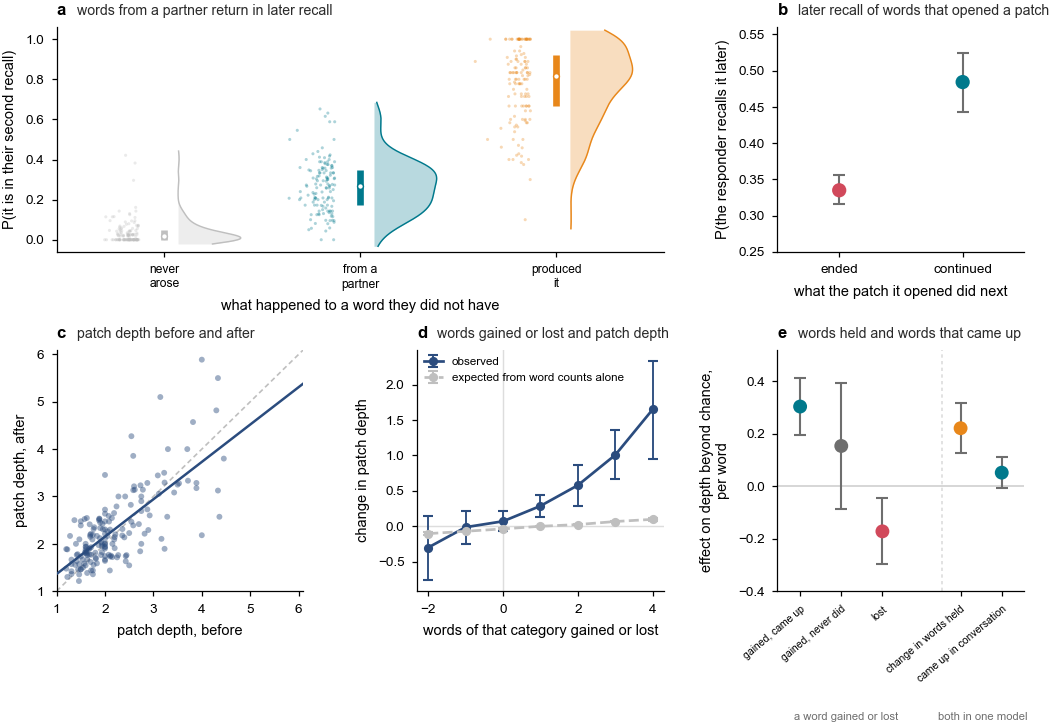

In [12]:
# two rows: panels a, b on top, c, d, e below
fig = plt.figure(figsize=(DOUBLE, 4.45))
outer = fig.add_gridspec(2, 1, height_ratios=[.93, 1.0], hspace=.42,
                         left=.075, right=.985, top=.945, bottom=.100)
# both rows share three columns; a spans two
g_top = outer[0].subgridspec(1, 3, wspace=.46)
g_bot = outer[1].subgridspec(1, 3, wspace=.46)

STORE, RULE = COL["third"], COL["solo"]
CONV, SPONT, LOST = COL["partner"], COL["grey"], COL["own"]
DIED, RAN = COL["own"], COL["partner"]

# ---------- a · acquisition by exposure ----------
a_ = fig.add_subplot(g_top[0, 0:2])
raincloud(a_, [EXPO.never.values, EXPO.heard.values, EXPO["said"].values],
          [COL["light"], CONV, COL["third"]],
          labels=["never\narose", "from a\npartner", "produced\nit"], ms=2.2, alpha_pts=.32)
a_.tick_params(axis="x", labelsize=5.8)
a_.set_ylim(-.06, 1.06)
a_.set_ylabel("P(it is in their second recall)")
a_.set_xlabel("what happened to a word they did not have")
panel(a_, "a", "words from a partner return in later recall")

# ---------- b · later recall by patch continuation ----------
b_ = fig.add_subplot(g_top[0, 2])
ys = SURV.rate.values
b_.errorbar(range(2), ys, yerr=[ys - SURV.lo.values, SURV.hi.values - ys], fmt="none",
            ecolor=COL["grey"], capsize=2.8, elinewidth=1.0, zorder=3)
b_.scatter(range(2), ys, s=34, c=[DIED, RAN], zorder=4)
b_.set_xticks([0, 1]); b_.set_xticklabels(["ended", "continued"])
b_.set_xlim(-.5, 1.5); b_.set_ylim(.24, .56)
b_.set_ylabel("P(the responder recalls it later)")
b_.set_xlabel("what the patch it opened did next")
panel(b_, "b", "later recall of words that opened a patch")

# ---------- c · patch depth before and after ----------
c_ = fig.add_subplot(g_bot[0, 0])
c_.scatter(TRAIT.pre_depth, TRAIT.post_depth, s=8, color=RULE, alpha=.45,
           edgecolors="none", zorder=3)
# axis limits from the data
_v = np.r_[TRAIT.pre_depth.values, TRAIT.post_depth.values]
lim = [np.floor(_v.min() * 2) / 2, np.ceil(_v.max() * 2) / 2 + 0.1]
c_.plot(lim, lim, ls=(0, (3, 2)), color=COL["light"], lw=.8, zorder=1)
z = np.polyfit(TRAIT.pre_depth, TRAIT.post_depth, 1)
xs = np.linspace(*lim, 50)
c_.plot(xs, np.polyval(z, xs), color=RULE, lw=1.2, zorder=4)
c_.set_xlim(*lim); c_.set_ylim(*lim)
c_.set_xlabel("patch depth, before")
c_.set_ylabel("patch depth, after")
panel(c_, "c", "patch depth before and after")

# ---------- d · change in depth by change in words held ----------
d_ = fig.add_subplot(g_bot[0, 1])
for col, cc, ls, lab in (("d_depth", RULE, "-", "observed"),
                         ("d_arith", COL["light"], "--", "expected from word counts alone")):
    g = binned(CELL, "d_stock", col, -4, 4)
    d_.errorbar(g.b, g.m, yerr=[g.m - g.lo, g.hi - g.m], fmt="o", linestyle=ls,
                color=cc, ms=3.4, capsize=2.2, elinewidth=.9, label=lab, zorder=4)
d_.axhline(0, color="#DDDDDD", lw=.7, zorder=1)
d_.axvline(0, color="#DDDDDD", lw=.7, zorder=1)
d_.set_xlabel("words of that category gained or lost")
d_.set_ylabel("change in patch depth")
d_.legend(loc="upper left", fontsize=5.6, handlelength=1.6, borderaxespad=.2)
panel(d_, "d", "words gained or lost and patch depth")

# ---------- e · coefficients ----------
e_ = fig.add_subplot(g_bot[0, 2])
# gained_conv counts gained words that came up in any of the person's conversations, written by
# either participant; gained_spont, gained words that never came up
terms = [(mo, "gained_conv", "gained,\ncame up", CONV),
         (mo, "gained_spont", "gained,\nnever did", SPONT),
         (mo, "lost", "lost", LOST),
         (m3, "d_stock", "change in\nwords held", STORE),
         (m3, "exposed", "came up in\nconversation", CONV)]
xs_ = [0, 1, 2, 3.9, 4.9]
ys = [m.params[t] for m, t, _, _ in terms]
es = [1.96 * m.bse[t] for m, t, _, _ in terms]
e_.errorbar(xs_, ys, yerr=es, fmt="none", ecolor=COL["grey"], capsize=3,
            elinewidth=1.0, zorder=3)
e_.scatter(xs_, ys, s=32, c=[c for _, _, _, c in terms], zorder=4)
e_.axhline(0, color="#CFCFCF", lw=.8, zorder=1)
e_.axvline(3.45, color="#DDDDDD", lw=.8, ls=(0, (2, 2)), zorder=1)
e_.set_xticks(xs_); e_.set_xticklabels([l.replace("\n", " ") for _, _, l, _ in terms], fontsize=5.0,
                                     rotation=40, ha="right", rotation_mode="anchor")
e_.set_xlim(-.55, 5.45); e_.set_ylim(-.40, .52)
e_.set_ylabel("effect on depth beyond chance,\nper word")
for x, lab in ((0.28, "a word gained or lost"), (0.83, "both in one model")):
    e_.text(x, -.50, lab, ha="center", va="top", fontsize=5.4,
            color=COL["grey"], transform=e_.transAxes)
panel(e_, "e", "words held and words that came up")

close_corner(fig)
save(fig, "Figure_4")
plt.show()